# Transient Pumping-Test Analysis Using Theis and Cooper–Jacob

**Hydraulic Methods · Hydrogeology · Karlsruhe Institute of Technology (KIT)**

This notebook demonstrates two methods for analyzing transient pumping tests in a **confined aquifer**: fitting the complete **Theis solution** and applying the **Cooper–Jacob straight-line method**. It also calculates drawdown for specified aquifer parameters.

### Learning objectives

After working through this notebook, you will be able to:

1. calculate and plot a drawdown time series using the Theis equation;
2. estimate transmissivity **T** and storativity **S** from observations;
3. display a Theis fit on **log–log axes** and a Cooper–Jacob analysis on **semi-logarithmic axes**;
4. check the applicability of the Cooper–Jacob approximation using the parameter **u** and assess the effects of selecting different observations.

**Required packages:** `numpy`, `scipy`, `matplotlib`. All data are included in the notebook. Run the cells from top to bottom.

*Based on:* [Christian Hill: Linear and non-linear fitting of the Theis equation](https://scipython.com/blog/linear-and-non-linear-fitting-of-the-theis-equation/); revised and extended for teaching.

## 1. Theoretical background

### 1.1 Theis equation

The Theis equation describes the time-dependent drawdown caused by pumping groundwater at a constant rate:

$$
s(u)=\frac{Q}{4\pi T}\,W(u)
\qquad\text{with}\qquad
u=\frac{r^2 S}{4Tt}
$$

The **well function W(u)** is the exponential integral:

$$
W(u)=E_1(u)=\int_u^\infty\frac{e^{-x}}{x}\,\mathrm{d}x
$$

| Symbol | Meaning | Unit |
|:---:|:---|:---:|
| **s** | Drawdown | m |
| **r** | Distance from the pumping well | m |
| **t** | Time since pumping started | s |
| **Q** | Constant pumping rate (extraction positive) | m³/s |
| **T** | Transmissivity | m²/s |
| **S** | Storativity | – |
| **u** | Dimensionless time parameter | – |

**Assumptions:** confined, homogeneous and isotropic aquifer; radial flow; fully penetrating well; constant pumping rate; initially horizontal potentiometric surface; and no effective hydraulic boundaries. Effects such as wellbore storage, leakage, and well losses are not accounted for.

### 1.2 Cooper–Jacob approximation

For small values of **u**, the well function can be approximated using its series expansion:

$$
W(u)\approx-\gamma-\ln(u),
\qquad \gamma\approx0.577216
$$

Here **γ** is the **Euler–Mascheroni constant**. Substituting into the Theis equation gives:

$$
s(u)\approx\frac{Q}{4\pi T}\left[-\gamma-\ln(u)\right]
$$

Using the base-10 logarithm and the relationship between **u** and **t**, we obtain:

$$
s(u)\approx\frac{2.303\,Q}{4\pi T}
\log_{10}\!\left(\frac{2.25\,Tt}{r^2S}\right)
$$

This produces a straight line when **s** is plotted against the logarithm of time **t**. The slope **m** (increase in drawdown per logarithmic decade) and the extrapolated time intercept **t₀**, at which **s = 0**, give:

$$
T=\frac{Q\ln(10)}{4\pi m}
\qquad\text{and}\qquad
S=\frac{4e^{-\gamma}Tt_0}{r^2}\approx\frac{2.25\,Tt_0}{r^2}
$$

**Applicability of the Cooper–Jacob approximation:** The approximation is valid for small **u**. Different guidelines are reported in the literature: **u ≤ 0.01** (Kruseman & de Ridder, 1990/1991), **u ≤ 0.02** (Freeze & Cherry, 1979), and **u ≤ 0.05** (Fetter, 2001; summarized and discussed by Gomo, 2020). We use **u ≤ 0.02** below. This threshold is a guideline for judging the approximation, not a statistical point-selection method. A visually convincing straight line does not establish the validity of the underlying model assumptions. Because **T** and **S** are initially unknown for a real pumping test, we calculate **u** only after estimating the parameters.

## 2. Python functions

The well function is calculated with `scipy.special.exp1`. The full Theis solution is fitted using nonlinear least squares. We optimize the **logarithms of S and T** so that the estimated parameters remain positive.

For Cooper–Jacob, we perform linear regression of **s** against `log10(t)`. The parameter `n_exclude` specifies how many **initial observations** to exclude. The function also returns the slope and the time intercept. Fit quality is evaluated using the **RMSE**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import exp1

# Consistent figure styling
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.frameon": False,
})

U_LIMIT = 0.02  # Selected guideline threshold (Freeze & Cherry, 1979)


def theis_drawdown(t, Q, r, S, T):
    """Calculate Theis drawdown (s in m; t in s)."""
    t = np.asarray(t, dtype=float)
    if np.any(t <= 0) or min(Q, r, S, T) <= 0:
        raise ValueError("Q, r, S, T, and all times must be positive.")
    u = r**2 * S / (4 * T * t)
    return Q / (4 * np.pi * T) * exp1(u)


def rmse(observed, predicted):
    """Root mean square error of drawdown (m)."""
    return np.sqrt(np.mean((np.asarray(observed) - np.asarray(predicted))**2))


def fit_theis(t, s, Q, r, S0=1e-3, T0=1e-3):
    """Nonlinear fit of the complete Theis solution."""
    def model(time, logS, logT):
        return theis_drawdown(time, Q, r, np.exp(logS), np.exp(logT))

    result, _ = curve_fit(
        model, t, s, p0=np.log([S0, T0]),
        bounds=(np.log([1e-12, 1e-12]), np.log([10.0, 10.0])),
        max_nfev=10000,
    )
    return tuple(np.exp(result))  # S, T


def fit_cooper_jacob(t, s, Q, r, n_exclude=3):
    """Cooper–Jacob straight-line fit starting at index n_exclude."""
    t = np.asarray(t, dtype=float)
    s = np.asarray(s, dtype=float)
    if t.ndim != 1 or len(t) != len(s) or np.any(np.diff(t) <= 0):
        raise ValueError("t and s must be arrays of the same length with strictly increasing times.")
    if min(Q, r) <= 0 or np.any(t <= 0):
        raise ValueError("Q, r, and t must be positive.")
    if not isinstance(n_exclude, (int, np.integer)) or n_exclude < 0:
        raise ValueError("n_exclude must be a non-negative integer.")
    if len(t) - n_exclude < 3:
        raise ValueError("At least three observations are required for regression.")

    selected = np.arange(len(t)) >= n_exclude
    m, c = np.polyfit(np.log10(t[selected]), s[selected], 1)
    if m <= 0:
        raise ValueError("The slope must be positive.")

    T = Q * np.log(10) / (4 * np.pi * m)
    t0 = 10 ** (-c / m)
    S = 4 * np.exp(-np.euler_gamma) * T * t0 / r**2
    return {"S": S, "T": T, "m": m, "c": c, "t0": t0, "selected": selected}


def cj_drawdown(t, result):
    """Evaluate the fitted Cooper–Jacob line."""
    return result["m"] * np.log10(np.asarray(t, dtype=float)) + result["c"]


def check_cj_validity(t, Q, r, fit, limit=U_LIMIT):
    """u values for selected observations, calculated from CJ parameters."""
    times = np.asarray(t)[fit["selected"]]
    u = r**2 * fit["S"] / (4 * fit["T"] * times)
    n_ok = np.count_nonzero(u <= limit)
    n_total = len(u)
    print(f"Applicability check for the Cooper–Jacob approximation (u ≤ {limit:.2f})")
    print(f"  Observations used: {n_total}")
    print(f"  Meeting the criterion: {n_ok}")
    print(f"  Maximum u value: {u.max():.4f}")
    if n_ok < n_total:
        print("  WARNING: Some observations exceed the selected u guideline.")
    else:
        print("  All selected observations satisfy the u criterion.")
    return u

## 3. Example 1 – synthetic pumping-test data

We generate drawdown values with **known** values of **T** and **S** and add a small measurement error. A fixed random seed makes the synthetic observations reproducible. The parameters can be changed in the following code cell.

In [2]:
# Input values from the original example
Q_synth = 0.002   # m³/s
r_synth = 10.0    # m
S_true = 0.001    # –
T_true = 0.001    # m²/s
t_synth = np.array([20, 40, 80, 120, 160, 200, 300, 400,
                    500, 600, 700, 800, 900, 1000, 1200], dtype=float)  # s

random_seed = 42
relative_noise = 0.01  # Standard deviation of relative measurement error: 1 %
rng = np.random.default_rng(random_seed)
s_synth_exact = theis_drawdown(t_synth, Q_synth, r_synth, S_true, T_true)
s_synth = s_synth_exact * (1 + relative_noise * rng.standard_normal(len(t_synth)))

assert np.all(s_synth > 0)

### 3.1 Observations – linear plot

First, we plot the observations without a fitted curve. **Both axes are linear.**

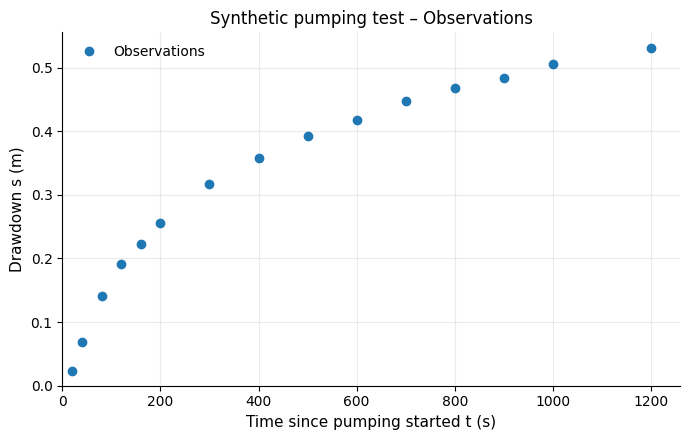

In [3]:
fig, ax = plt.subplots()
ax.plot(t_synth, s_synth, "o", ms=6, label="Observations")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Synthetic pumping test – Observations")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Theis fit – log–log plot

The **complete Theis solution** is fitted to **all observations**. To assess the shape of the curve, we plot drawdown against time with **both axes logarithmic**.

Theis fit (synthetic data, all observations)
T = 9.86962e-04 m²/s (Input value: 1.00000e-03 m²/s)
S = 1.01590e-03 (Input value: 1.00000e-03)
RMSE = 0.00242 m


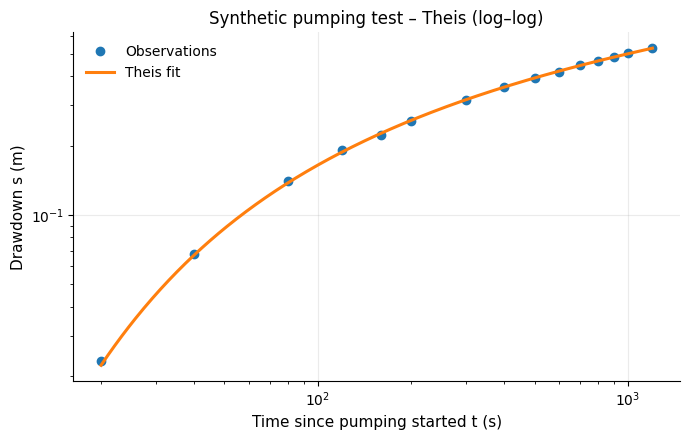

In [4]:
S_theis_synth, T_theis_synth = fit_theis(t_synth, s_synth, Q_synth, r_synth)
s_theis_synth = theis_drawdown(t_synth, Q_synth, r_synth, S_theis_synth, T_theis_synth)
t_plot_synth = np.geomspace(t_synth.min(), t_synth.max(), 400)

print("Theis fit (synthetic data, all observations)")
print(f"T = {T_theis_synth:.5e} m²/s (Input value: {T_true:.5e} m²/s)")
print(f"S = {S_theis_synth:.5e} (Input value: {S_true:.5e})")
print(f"RMSE = {rmse(s_synth, s_theis_synth):.5f} m")

fig, ax = plt.subplots()
ax.loglog(t_synth, s_synth, "o", ms=6, label="Observations")
ax.loglog(t_plot_synth, theis_drawdown(t_plot_synth, Q_synth, r_synth,
                                      S_theis_synth, T_theis_synth),
          "-", lw=2.2, label="Theis fit")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Synthetic pumping test – Theis (log–log)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Cooper–Jacob analysis – semi-logarithmic plot

We fit two straight lines to illustrate the influence of early observations:

- **All observations:** for comparison, not automatically a valid Cooper–Jacob analysis.
- **Excluding the first three observations:** change this number using `n_exclude_synth = 3`.

**Only the time axis is logarithmic**; the drawdown axis remains linear. The full Theis curve is **not** included in this plot.

**Important applicability check:** We subsequently check whether the observations used for regression meet the guideline **u ≤ 0.02**, calculating **u from the estimated Cooper–Jacob values of T and S**. These fitted lines mainly illustrate the **effect of observation selection**. A good straight-line fit alone does not establish the applicability of the approximation.

Cooper–Jacob analysis (synthetic data)
All observations          : T = 1.21790e-03 m²/s, S = 6.57127e-04
Excluding first 3 observations: T = 1.06132e-03 m²/s, S = 8.51357e-04
Selected: 12 of 15 observations
Applicability check for the Cooper–Jacob approximation (u ≤ 0.02)
  Observations used: 12
  Meeting the criterion: 1
  Maximum u value: 0.1671


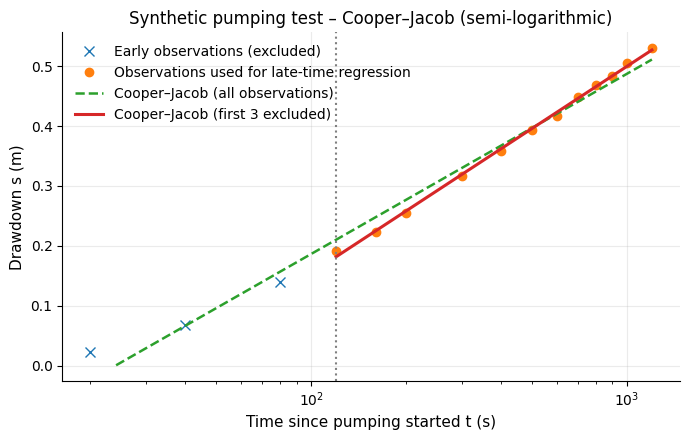

In [5]:
n_exclude_synth = 3  # Number of excluded early observations
cj_synth_all = fit_cooper_jacob(t_synth, s_synth, Q_synth, r_synth, n_exclude=0)
cj_synth_late = fit_cooper_jacob(t_synth, s_synth, Q_synth, r_synth,
                                  n_exclude=n_exclude_synth)
selected_synth = cj_synth_late["selected"]

print("Cooper–Jacob analysis (synthetic data)")
for title, fit in [("All observations", cj_synth_all),
                   ("Excluding first 3 observations", cj_synth_late)]:
    print(f"{title:<26}: T = {fit['T']:.5e} m²/s, S = {fit['S']:.5e}")
print(f"Selected: {selected_synth.sum()} of {len(t_synth)} observations")
check_cj_validity(t_synth, Q_synth, r_synth, cj_synth_late)

fig, ax = plt.subplots()
ax.semilogx(t_synth[~selected_synth], s_synth[~selected_synth],
            "x", ms=7, label="Early observations (excluded)")
ax.semilogx(t_synth[selected_synth], s_synth[selected_synth],
            "o", ms=6, label="Observations used for late-time regression")

# Show the fitted lines only where predicted drawdown is positive.
t_fit_all = np.geomspace(t_synth.min(), t_synth.max(), 350)
t_fit_late = np.geomspace(t_synth[n_exclude_synth], t_synth.max(), 300)
s_fit_all = cj_drawdown(t_fit_all, cj_synth_all)
ax.semilogx(t_fit_all, np.where(s_fit_all > 0, s_fit_all, np.nan),
            "--", lw=1.8, label="Cooper–Jacob (all observations)")
ax.semilogx(t_fit_late, cj_drawdown(t_fit_late, cj_synth_late),
            "-", lw=2.2, label=f"Cooper–Jacob (first {n_exclude_synth} excluded)")
ax.axvline(t_synth[n_exclude_synth], ls=":", color="0.5")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Synthetic pumping test – Cooper–Jacob (semi-logarithmic)")
ax.legend()
plt.tight_layout()
plt.show()

### 3.4 Interpretation

The Theis fit uses the full well function and can therefore include early-time observations. The Cooper–Jacob method replaces the initially curved Theis response with a straight line. Excluding early observations changes the line and hence the parameter estimates.

**Important:** For the present time series, excluding only the first three observations does not guarantee that **u ≤ 0.02**. Demonstrating the Cooper–Jacob approximation within this threshold requires sufficiently late observations or a longer pumping test. The original data are deliberately retained.

## 4. Example 2 – pumping-test observations (exercise a)

The following observations and pumping-test details are taken **unchanged from the original notebook**. The pumping rate is **Q = 0.006 m³/s**, and the observation well is **r = 40 m** from the pumping well. Estimate **T** and **S**.

As in the synthetic example, we use three plots: **linear for the observations**, **log–log for Theis**, and **semi-logarithmic for Cooper–Jacob**.

In [6]:
# Input data for exercise a (unchanged)
Q_real = 0.006   # m³/s
r_real = 40.0    # m
t_real = np.array([10, 18, 32, 57, 100, 178, 316,
                   562, 1000, 1780, 3160, 5620, 10000], dtype=float)  # s
s_real = np.array([0.005, 0.02, 0.05, 0.09, 0.16, 0.23, 0.31,
                   0.40, 0.49, 0.58, 0.67, 0.75, 0.82], dtype=float)  # m

assert np.all(np.diff(t_real) > 0) and len(t_real) == len(s_real)
assert np.all(s_real > 0)

### 4.1 Observations – linear plot

We first plot only the observations, with **linear scales** for both time and drawdown.

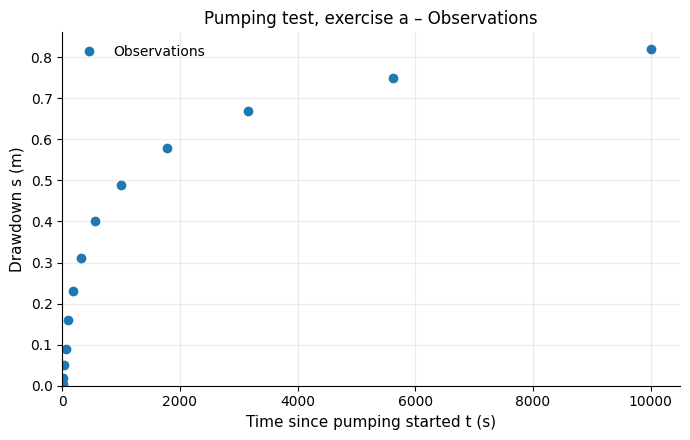

In [7]:
fig, ax = plt.subplots()
ax.plot(t_real, s_real, "o", ms=6, label="Observations")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Pumping test, exercise a – Observations")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Theis fit – log–log plot

The Theis curve is fitted by nonlinear regression to **all 13 observations**. Both axes are **logarithmic**. The **RMSE** is reported in metres.

Theis fit – exercise a
T = 3.08536e-03 m²/s
S = 1.94614e-04
RMSE (all observations) = 0.00692 m


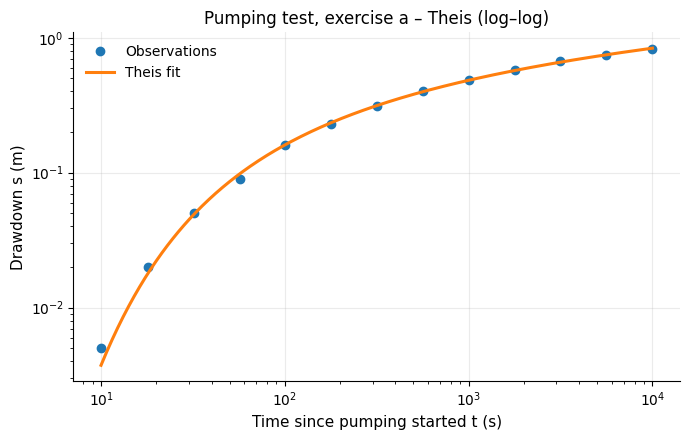

In [8]:
S_theis_real, T_theis_real = fit_theis(t_real, s_real, Q_real, r_real,
                                       S0=1e-4, T0=3e-3)
pred_theis_real = theis_drawdown(t_real, Q_real, r_real,
                                 S_theis_real, T_theis_real)
t_plot_real = np.geomspace(t_real.min(), t_real.max(), 400)

print("Theis fit – exercise a")
print(f"T = {T_theis_real:.5e} m²/s")
print(f"S = {S_theis_real:.5e}")
print(f"RMSE (all observations) = {rmse(s_real, pred_theis_real):.5f} m")

fig, ax = plt.subplots()
ax.loglog(t_real, s_real, "o", ms=6, label="Observations")
ax.loglog(t_plot_real, theis_drawdown(t_plot_real, Q_real, r_real,
                                     S_theis_real, T_theis_real),
          "-", lw=2.2, label="Theis fit")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Pumping test, exercise a – Theis (log–log)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 Cooper–Jacob analysis – semi-logarithmic plot

For this straight-line fit, **only the first three observations are excluded**. They remain visible in the plot for reference. All remaining observations are used in the regression. The x-axis is logarithmic, and the y-axis is linear. **The Theis curve is not plotted here.**

Since not every selected observation necessarily satisfies **u ≤ 0.02**, we then calculate **u from the estimated Cooper–Jacob parameters** and report any exceedances. For comparison, fit errors for both methods are calculated **using the same selected observations**.

Cooper–Jacob analysis – exercise a
Selected: 10 of 13 observations
T = 3.28164e-03 m²/s
S = 1.56924e-04
Slope m = 0.33502 m per decade
Time intercept t₀ = 34.07 s
RMSE (CJ, selected interval) = 0.00921 m
RMSE (Theis, same interval) = 0.00785 m
Applicability check for the Cooper–Jacob approximation (u ≤ 0.02)
  Observations used: 10
  Meeting the criterion: 5
  Maximum u value: 0.3356


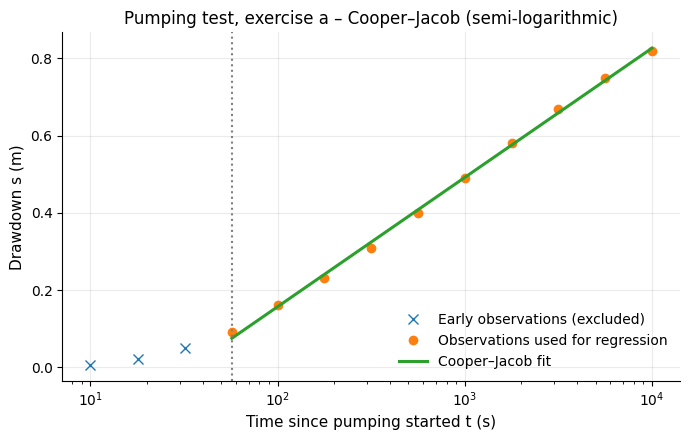

In [9]:
n_exclude_real = 3  # Number of excluded early observations
cj_real = fit_cooper_jacob(t_real, s_real, Q_real, r_real,
                            n_exclude=n_exclude_real)
selected_real = cj_real["selected"]
pred_cj_real = cj_drawdown(t_real[selected_real], cj_real)

print("Cooper–Jacob analysis – exercise a")
print(f"Selected: {selected_real.sum()} of {len(t_real)} observations")
print(f"T = {cj_real['T']:.5e} m²/s")
print(f"S = {cj_real['S']:.5e}")
print(f"Slope m = {cj_real['m']:.5f} m per decade")
print(f"Time intercept t₀ = {cj_real['t0']:.2f} s")
print(f"RMSE (CJ, selected interval) = {rmse(s_real[selected_real], pred_cj_real):.5f} m")
print(f"RMSE (Theis, same interval) = {rmse(s_real[selected_real], pred_theis_real[selected_real]):.5f} m")
check_cj_validity(t_real, Q_real, r_real, cj_real)

fig, ax = plt.subplots()
ax.semilogx(t_real[~selected_real], s_real[~selected_real],
            "x", ms=7, label="Early observations (excluded)")
ax.semilogx(t_real[selected_real], s_real[selected_real],
            "o", ms=6, label="Observations used for regression")
t_fit_cj_real = np.geomspace(t_real[n_exclude_real], t_real.max(), 350)
ax.semilogx(t_fit_cj_real, cj_drawdown(t_fit_cj_real, cj_real),
            "-", lw=2.2, label="Cooper–Jacob fit")
ax.axvline(t_real[n_exclude_real], ls=":", color="0.5")
ax.set(xlabel="Time since pumping started t (s)", ylabel="Drawdown s (m)",
       title="Pumping test, exercise a – Cooper–Jacob (semi-logarithmic)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.4 Residuals – additional quality check

A residual is the difference between **observed and modelled drawdown** (observed minus modelled). The two methods are compared in a separate diagnostic plot. **No Theis drawdown curve is displayed here**, only the residuals at observation times; both axes are linear.

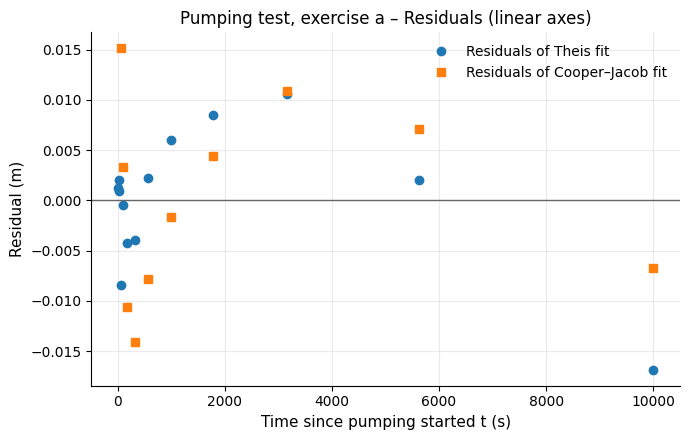

In [10]:
fig, ax = plt.subplots()
ax.plot(t_real, s_real - pred_theis_real, "o", ms=6,
        label="Residuals of Theis fit")
ax.plot(t_real[selected_real], s_real[selected_real] - pred_cj_real,
        "s", ms=5.5, label="Residuals of Cooper–Jacob fit")
ax.axhline(0, color="0.4", lw=1)
ax.set(xlabel="Time since pumping started t (s)", ylabel="Residual (m)",
       title="Pumping test, exercise a – Residuals (linear axes)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Example 3 – predicting drawdown (exercise b)

In a **forward calculation**, **Q**, **r**, **S**, **T**, and time **t** are given. Drawdown **s** is calculated from the Theis equation. Here, we calculate drawdown **after one day** (86,400 s). This example is independent of the previously estimated parameters.

In [11]:
# Input data for exercise b (unchanged)
Q_predict = 0.0053  # m³/s
r_predict = 100.0  # m
S_predict = 0.0001  # –
T_predict = 0.001   # m²/s
t_predict = 24 * 60 * 60  # s (1 day)

s_predict = float(theis_drawdown(t_predict, Q_predict, r_predict,
                                 S_predict, T_predict))
print("Exercise b – drawdown prediction")
print(f"Q = {Q_predict:.4f} m³/s, r = {r_predict:.1f} m")
print(f"T = {T_predict:.3e} m²/s, S = {S_predict:.3e}")
print(f"t = {t_predict:,.0f} s")
print(f"Drawdown after one day: s = {s_predict:.3f} m")

Exercise b – drawdown prediction
Q = 0.0053 m³/s, r = 100.0 m
T = 1.000e-03 m²/s, S = 1.000e-04
t = 86,400 s
Drawdown after one day: s = 2.223 m


## 6. Summary and notes

| Analysis | Plot type | Observations used |
|:---|:---|:---|
| Observed drawdown | **linear / linear** | all |
| Full Theis solution | **log–log** | all |
| Cooper–Jacob straight line | **semi-logarithmic** (log time axis) | configurable; by default, from the 4th observation onwards |

- **Theis** can describe the full idealized response when its assumptions are met.
- **Cooper–Jacob** is an approximation for small **u**. We use the literature guideline **u ≤ 0.02** (Freeze & Cherry, 1979). Simply excluding the first three observations does **not** guarantee that the approximation is applicable.
- In this example, **T** is comparatively stable; **S** is more sensitive to the selected fitting interval and the extrapolation to the time intercept.
- **RMSE values** describe the fit to the observations; they do not replace a hydrogeological assessment of the model assumptions.

**Try it yourself:** Change `n_exclude_synth` or `n_exclude_real` to 2, 4, or 5 and compare the parameter estimates and the applicability check. In the synthetic example, also vary `random_seed` or `relative_noise`.

### References

**Original methods**

- Theis, C. V. (1935): *The relation between the lowering of the piezometric surface and the rate and duration of discharge of a well using ground-water storage.* Transactions, American Geophysical Union, 16(2), 519–524. [DOI](https://doi.org/10.1029/TR016i002p00519).
- Cooper, H. H., Jr. & Jacob, C. E. (1946): *A generalized graphical method for evaluating formation constants and summarizing well-field history.* Transactions, American Geophysical Union, 27(4), 526–534. [DOI](https://doi.org/10.1029/TR027i004p00526).

**Applicability of the Cooper–Jacob approximation**

- Kruseman, G. P. & de Ridder, N. A. (1990; reprinted 1991): *Analysis and Evaluation of Pumping Test Data.* 2nd, fully revised edition, ILRI Publication 47, Wageningen (with contributions by J. M. Verweij). [Online edition](https://gw-project.org/books/analysis-and-evaluation-of-pumping-test-data/). Guideline: **u ≤ 0.01**.
- Freeze, R. A. & Cherry, J. A. (1979): *Groundwater.* Prentice-Hall, Englewood Cliffs, New Jersey. [Online edition](https://fc79.gw-project.org/). Guideline: **u ≤ 0.02**.
- Fetter, C. W. (2001): *Applied Hydrogeology.* 4th edition, Prentice Hall, Upper Saddle River, New Jersey. Guideline: **u ≤ 0.05**.
- Gomo, M. (2020): *On the practical application of the Cooper and Jacob distance-drawdown method to analyse aquifer-pumping test data.* Groundwater for Sustainable Development, 11, 100478. [DOI](https://doi.org/10.1016/j.gsd.2020.100478). Discusses different **u** thresholds and the importance of the development of radial flow conditions for applicability.

The thresholds listed are **guidelines from the literature**, not sharp physical limits. Other model assumptions must be checked independently.